In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix
import time

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [3]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_64_train/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_64_test/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    seed=42,
    shuffle=False
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 14057 files belonging to 2 classes.
Using 11246 files for training.
Using 2811 files for validation.
Found 3515 files belonging to 2 classes.


In [4]:
# #Correct model
# model = keras.models.Sequential()
# model.add(keras.Input(shape=(64,64,3)))
# model.add(layers.Conv2D(filters=8,kernel_size=8, 
#                         activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Flatten())
# model.add(layers.Dense(units=32, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))

# model.add(layers.Dense(units=1, activation="sigmoid"))

model = keras.models.Sequential()
model.add(keras.Input(shape=(64,64,3)))
model.add(layers.Conv2D(filters=8, kernel_size=7, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dense(units=2, activation='softmax'))


model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = tf.keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=7, restore_best_weights=True)
def scheduler(epoch, lr):
   if epoch < 10:
     return lr
   else:
     return 0.0001
learning_scheduler = tf.keras.callbacks.LearningRateScheduler(scheduler, verbose=0)

In [5]:
start = time.time()
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    # class_weight= {0: 0.9, 1: 1}
    )
endTime = time.time()-start
print(f'Time elapsed: {endTime//60}m {round(endTime%60,2)}s')

Epoch 1/50
703/703 [==============================] - 11s 11ms/step - loss: 0.4291 - categorical_accuracy: 0.8032 - val_loss: 0.2398 - val_categorical_accuracy: 0.9018
Epoch 2/50
703/703 [==============================] - 8s 11ms/step - loss: 0.2184 - categorical_accuracy: 0.9094 - val_loss: 0.2655 - val_categorical_accuracy: 0.9011
Epoch 3/50
703/703 [==============================] - 8s 12ms/step - loss: 0.1951 - categorical_accuracy: 0.9231 - val_loss: 0.2229 - val_categorical_accuracy: 0.9256
Epoch 4/50
703/703 [==============================] - 9s 13ms/step - loss: 0.1931 - categorical_accuracy: 0.9237 - val_loss: 0.2086 - val_categorical_accuracy: 0.9267
Epoch 5/50
703/703 [==============================] - 9s 12ms/step - loss: 0.1753 - categorical_accuracy: 0.9295 - val_loss: 0.2104 - val_categorical_accuracy: 0.9271
Epoch 6/50
703/703 [==============================] - 9s 12ms/step - loss: 0.1647 - categorical_accuracy: 0.9344 - val_loss: 0.2154 - val_categorical_accuracy: 0.92

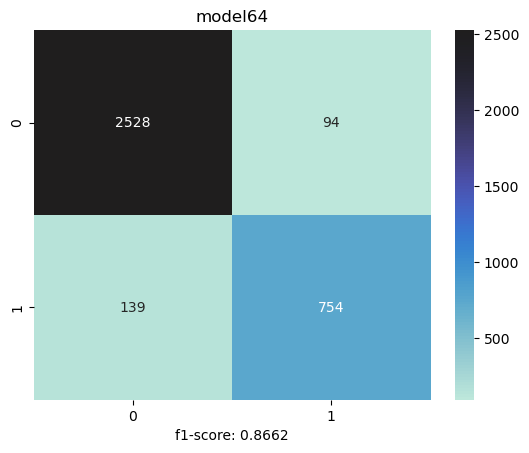

In [7]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
# plt.savefig('./documentation/model64_test.png')
plt.show()

In [7]:
model.save("./trained_models/model64_test")

INFO:tensorflow:Assets written to: ./trained_models/model64\assets


INFO:tensorflow:Assets written to: ./trained_models/model64\assets


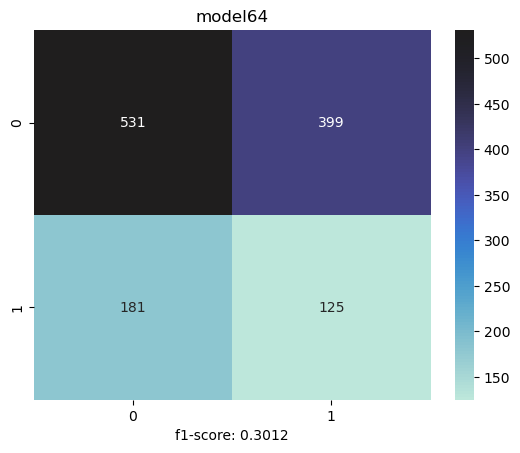

In [5]:
saved_model64 = keras.models.load_model("./trained_models/model64_test/")
# saved_model64.save("./trained_models/model64_2")
array = test_model(saved_model64, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.show()